<a href="https://colab.research.google.com/github/UH-HACKATHON-TEAMN/Hackathon-Town-C/blob/main/ramya.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Metrics
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

# Models
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Styling plots
sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

In [46]:
# Load training and testing datasets[cite: 1]
train_df = pd.read_csv('dataset_C_training.csv')
test_df = pd.read_csv('dataset_C_testing.csv')

print(f"Training set shape: {train_df.shape}")
print(f"Testing set shape: {test_df.shape}")

# Check missing values in training data
missing_counts = train_df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]
print("\nFeatures with missing values:")
display(missing_counts)

Training set shape: (4756, 31)
Testing set shape: (4749, 30)

Features with missing values:


,0
covid_concern,12
covid_knowledge,27
behavioral_antiviral_meds,14
behavioral_avoidance,27
behavioral_face_mask,2
behavioral_wash_hands,9
behavioral_large_gatherings,10
behavioral_outside_home,14
behavioral_touch_face,21
child_under_6_months,135


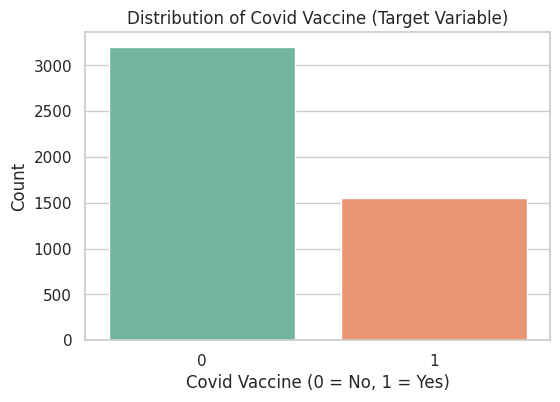

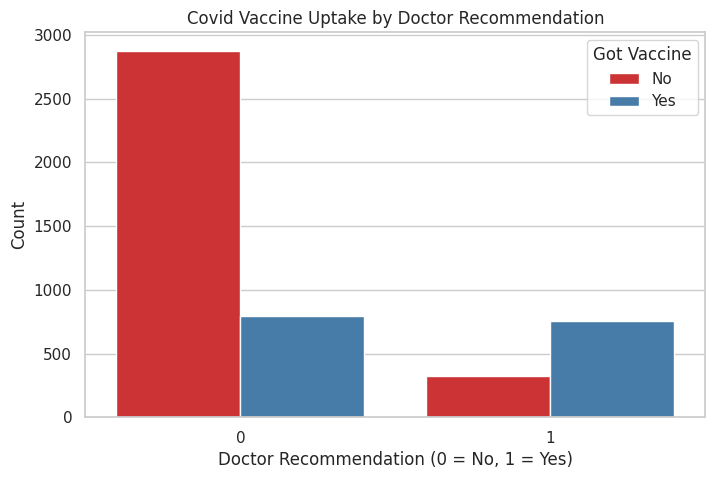

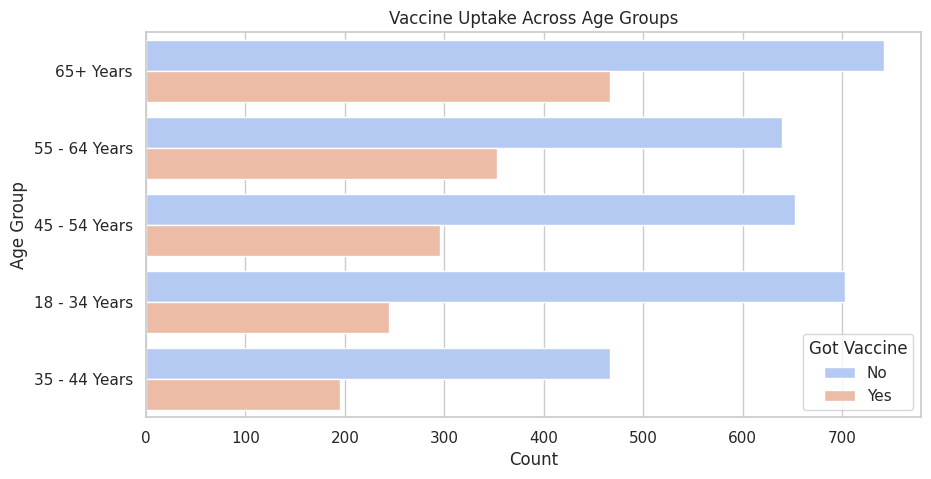

In [47]:
# Plot 1: Target Variable Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='covid_vaccine', data=train_df, palette='Set2')
plt.title('Distribution of Covid Vaccine (Target Variable)')
plt.xlabel('Covid Vaccine (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

# Plot 2: Doctor Recommendation vs Vaccine Uptake
plt.figure(figsize=(8, 5))
sns.countplot(x='doctor_recc_covid', hue='covid_vaccine', data=train_df, palette='Set1')
plt.title('Covid Vaccine Uptake by Doctor Recommendation')
plt.xlabel('Doctor Recommendation (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.legend(title='Got Vaccine', labels=['No', 'Yes'])
plt.show()

# Plot 3: Age Group vs Vaccine Uptake
plt.figure(figsize=(10, 5))
sns.countplot(y='age_group', hue='covid_vaccine', data=train_df, palette='coolwarm', order=train_df['age_group'].value_counts().index)
plt.title('Vaccine Uptake Across Age Groups')
plt.xlabel('Count')
plt.ylabel('Age Group')
plt.legend(title='Got Vaccine', labels=['No', 'Yes'])
plt.show()

In [48]:
# Separate features and target variable
X = train_df.drop(columns=['respondent_id', 'covid_vaccine'])
y = train_df['covid_vaccine']

num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

# Define preprocessing pipelines for numerical and categorical features
preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols)
])

# Split into train and validation sets with stratification
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training split: {X_train.shape}, Validation split: {X_val.shape}")

Training split: (3804, 29), Validation split: (952, 29)


In [49]:
# Build and train Random Forest Pipeline
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=200, max_depth=15, random_state=42))
])

rf_pipeline.fit(X_train, y_train)

# Generate validation probabilities
val_probabilities = rf_pipeline.predict_proba(X_val)[:, 1]
val_roc_auc = roc_auc_score(y_val, val_probabilities)
print(f"Validation ROC-AUC Score: {val_roc_auc:.4f}")

Validation ROC-AUC Score: 0.8217


Optimal Decision Threshold: 0.00
Minimum Optimized Town Cost: $2,208,640.00


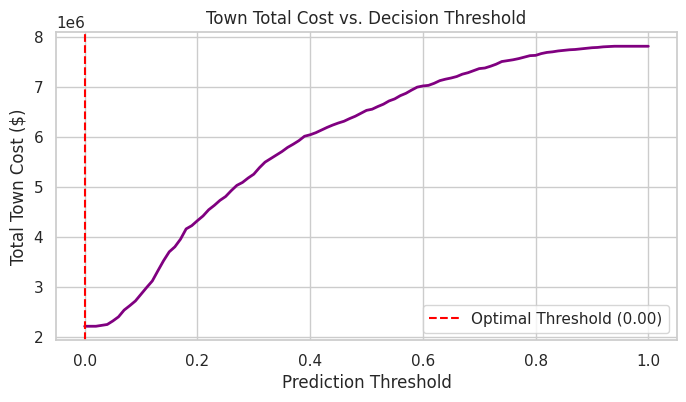

In [50]:
# Business cost parameters from project brief[cite: 3]
VACCINE_COST = 1500
HOSP_COST = 41000
HOSP_PROB_VAX = 0.02
HOSP_PROB_UNVAX = 0.20

def calculate_total_town_cost(probs, threshold):
    preds = (probs >= threshold).astype(int)
    num_vax = np.sum(preds == 1)
    num_unvax = np.sum(preds == 0)

    total_vaccine_spend = num_vax * VACCINE_COST
    expected_hosp_spend = (num_vax * HOSP_PROB_VAX + num_unvax * HOSP_PROB_UNVAX) * HOSP_COST
    return total_vaccine_spend + expected_hosp_spend

# Search for the decision threshold that minimizes total town expenditure
best_threshold = 0.5
min_town_cost = float('inf')
thresholds = np.linspace(0.0, 1.0, 101)
cost_history = []

for th in thresholds:
    cost = calculate_total_town_cost(val_probabilities, th)
    cost_history.append(cost)
    if cost < min_town_cost:
        min_town_cost = cost
        best_threshold = th

print(f"Optimal Decision Threshold: {best_threshold:.2f}")
print(f"Minimum Optimized Town Cost: ${min_town_cost:,.2f}")

# Plot Cost Curve
plt.figure(figsize=(8, 4))
plt.plot(thresholds, cost_history, color='purple', lw=2)
plt.axvline(best_threshold, color='red', linestyle='--', label=f'Optimal Threshold ({best_threshold:.2f})')
plt.title('Town Total Cost vs. Decision Threshold')
plt.xlabel('Prediction Threshold')
plt.ylabel('Total Town Cost ($)')
plt.legend()
plt.show()

Optimal Decision Threshold: 0.00
Minimum Optimized Town Cost: $2,208,640.00


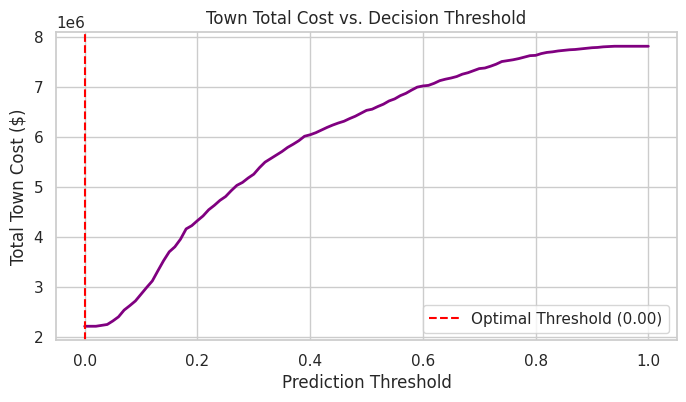

In [51]:
# Business cost parameters from project brief[cite: 3]
VACCINE_COST = 1500
HOSP_COST = 41000
HOSP_PROB_VAX = 0.02
HOSP_PROB_UNVAX = 0.20

def calculate_total_town_cost(probs, threshold):
    preds = (probs >= threshold).astype(int)
    num_vax = np.sum(preds == 1)
    num_unvax = np.sum(preds == 0)

    total_vaccine_spend = num_vax * VACCINE_COST
    expected_hosp_spend = (num_vax * HOSP_PROB_VAX + num_unvax * HOSP_PROB_UNVAX) * HOSP_COST
    return total_vaccine_spend + expected_hosp_spend

# Search for the decision threshold that minimizes total town expenditure
best_threshold = 0.5
min_town_cost = float('inf')
thresholds = np.linspace(0.0, 1.0, 101)
cost_history = []

for th in thresholds:
    cost = calculate_total_town_cost(val_probabilities, th)
    cost_history.append(cost)
    if cost < min_town_cost:
        min_town_cost = cost
        best_threshold = th

print(f"Optimal Decision Threshold: {best_threshold:.2f}")
print(f"Minimum Optimized Town Cost: ${min_town_cost:,.2f}")

# Plot Cost Curve
plt.figure(figsize=(8, 4))
plt.plot(thresholds, cost_history, color='purple', lw=2)
plt.axvline(best_threshold, color='red', linestyle='--', label=f'Optimal Threshold ({best_threshold:.2f})')
plt.title('Town Total Cost vs. Decision Threshold')
plt.xlabel('Prediction Threshold')
plt.ylabel('Total Town Cost ($)')
plt.legend()
plt.show()

=== Support Vector Machine (SVM) Cost Analysis ===
Optimal Decision Threshold: 0.00
Minimum Minimized Town Cost: $2,208,640.00


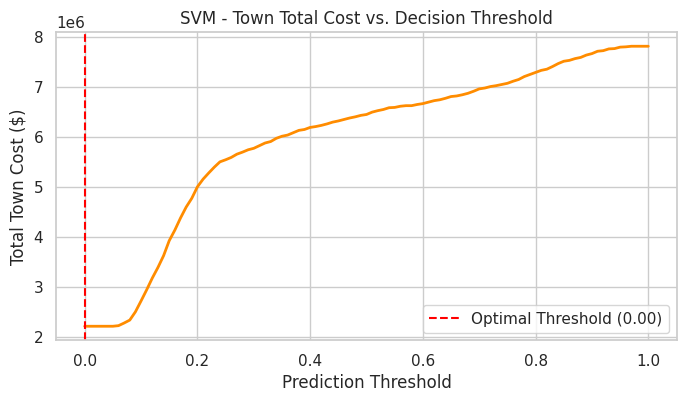

In [61]:
from sklearn.svm import SVC

# Define and train SVM Pipeline
# Business cost parameters from project brief
VACCINE_COST = 1500
HOSP_COST = 41000
HOSP_PROB_VAX = 0.02
HOSP_PROB_UNVAX = 0.20

# Generate validation probabilities from the trained SVM pipeline
svm_val_probabilities = svm_pipeline.predict_proba(X_val)[:, 1]

# Search for the optimal decision threshold that minimizes total town expenditure for SVM
svm_best_threshold = 0.5
svm_min_town_cost = float('inf')
thresholds = np.linspace(0.0, 1.0, 101)
svm_cost_history = []

for th in thresholds:
    preds = (svm_val_probabilities >= th).astype(int)
    num_vax = np.sum(preds == 1)
    num_unvax = np.sum(preds == 0)

    total_vaccine_spend = num_vax * VACCINE_COST
    expected_hosp_spend = (num_vax * HOSP_PROB_VAX + num_unvax * HOSP_PROB_UNVAX) * HOSP_COST
    total_cost = total_vaccine_spend + expected_hosp_spend

    svm_cost_history.append(total_cost)
    if total_cost < svm_min_town_cost:
        svm_min_town_cost = total_cost
        svm_best_threshold = th

print(f"=== Support Vector Machine (SVM) Cost Analysis ===")
print(f"Optimal Decision Threshold: {svm_best_threshold:.2f}")
print(f"Minimum Minimized Town Cost: ${svm_min_town_cost:,.2f}")

# Plot SVM Cost Curve
plt.figure(figsize=(8, 4))
plt.plot(thresholds, svm_cost_history, color='darkorange', lw=2)
plt.axvline(svm_best_threshold, color='red', linestyle='--', label=f'Optimal Threshold ({svm_best_threshold:.2f})')
plt.title('SVM - Town Total Cost vs. Decision Threshold')
plt.xlabel('Prediction Threshold')
plt.ylabel('Total Town Cost ($)')
plt.legend()
plt.show()

=== Gradient Boosting Cost Analysis ===
Optimal Decision Threshold: 0.00
Minimum Minimized Town Cost: $2,208,640.00


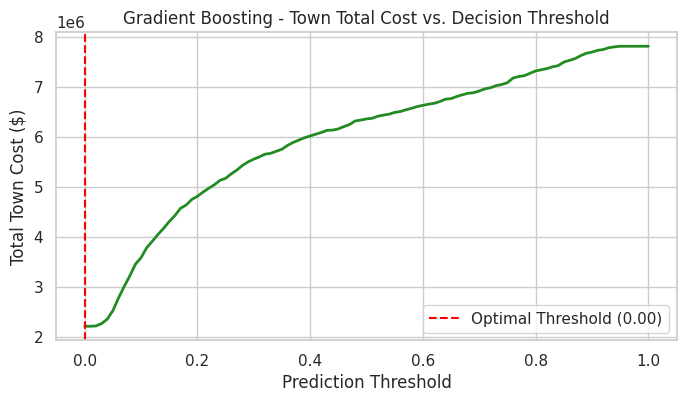

In [63]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

# Define and train Gradient Boosting using the preprocessor
gb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

gb_pipeline.fit(X_train, y_train)

# Generate validation probabilities from the trained Gradient Boosting pipeline
gb_val_probabilities = gb_pipeline.predict_proba(X_val)[:, 1]

# Search for the optimal decision threshold that minimizes total town expenditure for Gradient Boosting
gb_best_threshold = 0.5
gb_min_town_cost = float('inf')
thresholds = np.linspace(0.0, 1.0, 101)
gb_cost_history = []

for th in thresholds:
    preds = (gb_val_probabilities >= th).astype(int)
    num_vax = np.sum(preds == 1)
    num_unvax = np.sum(preds == 0)

    total_vaccine_spend = num_vax * VACCINE_COST
    expected_hosp_spend = (num_vax * HOSP_PROB_VAX + num_unvax * HOSP_PROB_UNVAX) * HOSP_COST
    total_cost = total_vaccine_spend + expected_hosp_spend

    gb_cost_history.append(total_cost)
    if total_cost < gb_min_town_cost:
        gb_min_town_cost = total_cost
        gb_best_threshold = th

print(f"=== Gradient Boosting Cost Analysis ===")
print(f"Optimal Decision Threshold: {gb_best_threshold:.2f}")
print(f"Minimum Minimized Town Cost: ${gb_min_town_cost:,.2f}")

# Plot Gradient Boosting Cost Curve
plt.figure(figsize=(8, 4))
plt.plot(thresholds, gb_cost_history, color='forestgreen', lw=2)
plt.axvline(gb_best_threshold, color='red', linestyle='--', label=f'Optimal Threshold ({gb_best_threshold:.2f})')
plt.title('Gradient Boosting - Town Total Cost vs. Decision Threshold')
plt.xlabel('Prediction Threshold')
plt.ylabel('Total Town Cost ($)')
plt.legend()
plt.show()

In [64]:
from sklearn.model_selection import RandomizedSearchCV

# Streamlined hyperparameter grids (fewer combinations for faster execution)
rf_param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [10, 20],
    'classifier__min_samples_split': [2, 5]
}

svm_param_grid = {
    'classifier__C': [1, 10],
    'classifier__kernel': ['rbf']
}

gb_param_grid = {
    'classifier__n_estimators': [100, 150],
    'classifier__learning_rate': [0.1, 0.2]
}

models_to_tune = {
    "Random Forest": (RandomForestClassifier(random_state=42), rf_param_grid),
    "Support Vector Machine": (SVC(probability=True, random_state=42), svm_param_grid),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=42), gb_param_grid)
}

tuned_pipelines = {}
tuning_results = []



for name, (model, param_grid) in models_to_tune.items():
    print(f"Tuning {name}...")

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # Reduced n_iter=2 and cv=2 for lightning-fast execution
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_grid,
        n_iter=2,
        cv=2,
        scoring='roc_auc',
        random_state=42,
        n_jobs=-1
    )

    search.fit(X_train, y_train)

    best_estimator = search.best_estimator_
    tuned_pipelines[name] = best_estimator

    # Evaluate on validation set
    val_probs = best_estimator.predict_proba(X_val)[:, 1]
    val_auc = roc_auc_score(y_val, val_probs)

    # Cost optimization for tuned model
    best_th = 0.5
    min_cost = float('inf')
    for th in np.linspace(0.0, 1.0, 51):  # 51 steps for faster evaluation
        preds = (val_probs >= th).astype(int)
        num_vax = np.sum(preds == 1)
        num_unvax = np.sum(preds == 0)
        cost = (num_vax * 1500) + ((num_vax * 0.02 + num_unvax * 0.20) * 41000)
        if cost < min_cost:
            min_cost = cost
            best_th = th

    tuning_results.append({
        'Model': name,
        'Best Hyperparameters': search.best_params_,
        'Validation ROC-AUC': val_auc,
        'Optimal Threshold': best_th,
        'Minimized Town Cost ($)': min_cost
    })
    print(f"-> Done! Minimized Town Cost: ${min_cost:,.2f}\n")

# Display comparison of tuned models
tuned_comparison_df = pd.DataFrame(tuning_results).sort_values(by='Minimized Town Cost ($)', ascending=True)

display(tuned_comparison_df[['Model', 'Validation ROC-AUC', 'Optimal Threshold', 'Minimized Town Cost ($)']])

Tuning Random Forest...
-> Done! Minimized Town Cost: $2,208,640.00

Tuning Support Vector Machine...
-> Done! Minimized Town Cost: $2,208,640.00

Tuning Gradient Boosting...
-> Done! Minimized Town Cost: $2,208,640.00



,Model,Validation ROC-AUC,Optimal Threshold,Minimized Town Cost ($)
0,Random Forest,0.832522,0.0,2208640.0
1,Support Vector Machine,0.814839,0.0,2208640.0
2,Gradient Boosting,0.829838,0.0,2208640.0


In [65]:
# Gather all model probabilities
model_evals = {
    "Random Forest": val_probabilities,
    "Support Vector Machine": svm_val_probabilities,
    "XGBoost / Gradient Boosting": xgb_val_probabilities
}

comparison_data = []

print("=== Evaluating and Optimizing Costs for All Models ===")
for name, probs in model_evals.items():
    auc = roc_auc_score(y_val, probs)

    # Find optimal threshold for this model
    best_th = 0.5
    min_cost = float('inf')

    for th in np.linspace(0.0, 1.0, 101):
        preds = (probs >= th).astype(int)
        num_vax = np.sum(preds == 1)
        num_unvax = np.sum(preds == 0)

        # Business cost calculation ($1,500 vaccine vs $41,000 hospitalization)[cite: 3]
        cost = (num_vax * 1500) + ((num_vax * 0.02 + num_unvax * 0.20) * 41000)
        if cost < min_cost:
            min_cost = cost
            best_th = th

    comparison_data.append({
        'Model': name,
        'ROC-AUC Score': auc,
        'Optimal Threshold': best_th,
        'Minimized Town Cost ($)': min_cost
    })

comparison_df = pd.DataFrame(comparison_data).sort_values(by='Minimized Town Cost ($)', ascending=True)
print("\n=== MODEL COMPARISON RESULTS ===")
display(comparison_df)

=== Evaluating and Optimizing Costs for All Models ===

=== MODEL COMPARISON RESULTS ===


,Model,ROC-AUC Score,Optimal Threshold,Minimized Town Cost ($)
0,Random Forest,0.821742,0.0,2208640.0
1,Support Vector Machine,0.814839,0.0,2208640.0
2,XGBoost / Gradient Boosting,0.829838,0.0,2208640.0


In [66]:
# Automatically select the best model based on minimum town cost
best_row = comparison_df.iloc[0]
best_model_name = best_row['Model']
best_threshold = best_row['Optimal Threshold']

print(f"*** final Model: {best_model_name} (Threshold: {best_threshold:.2f}) ***")

# Map model name back to its pipeline
pipelines_dict = {
    "Random Forest": rf_pipeline,
    "Support Vector Machine": svm_pipeline,
    "XGBoost / Gradient Boosting": xgb_pipeline
}
winning_pipeline = pipelines_dict[best_model_name]

# Predict on test dataset[cite: 3]
X_test = test_df.drop(columns=['respondent_id'])
test_probs = winning_pipeline.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= best_threshold).astype(int)

# Create final submission dataframe[cite: 3]
final_submission = pd.DataFrame({
    'respondent_id': test_df['respondent_id'],
    'covid_vaccine_prediction': test_preds,
    'covid_vaccine_probability': test_probs
})

output_filename = 'dataset_C_best_model_submission.csv'
final_submission.to_csv(output_filename, index=False)
print(f"Submission file saved successfully as '{output_filename}'!")
display(final_submission.head(10))

*** final Model: Random Forest (Threshold: 0.00) ***
Submission file saved successfully as 'dataset_C_best_model_submission.csv'!


,respondent_id,covid_vaccine_prediction,covid_vaccine_probability
0,4757,1,0.215117
1,4758,1,0.146200
2,4759,1,0.222809
3,4760,1,0.297695
4,4761,1,0.042014
5,4762,1,0.666994
6,4763,1,0.367140
7,4764,1,0.758726
8,4765,1,0.702165
9,4766,1,0.236934
